# **Mini-Lab:** Wireless Networks 

- Student 1
- Student 2

## Objective
Analyze how wireless network performance changes under different conditions (WiFi vs Mobile Data).

You will measure:
- Latency
- Stability (variance)
- Jitter

Then, you will relate your results to networking concepts such as SNR, interference, and mobility.

## Instructions

1. Connect to WiFi and run the measurements
2. Activate mobile hotspot (or connect to mobile data) and repeat
3. Compare results

Work in pairs if needed.

In [3]:
# Import required libraries
import subprocess # Allows running system commands like ping
import re # Used to extract numbers from text using patterns
import numpy as np # Used for numerical calculations
import matplotlib.pyplot as plt # Used for plotting graphs


In [2]:
%pip install numpy matplotlib


Defaulting to user installation because normal site-packages is not writeable
  Using cached numpy-2.5.4-cp312-cp312-win_amd64.whl.metadata (6.6 kB)
  Using cached matplotlib-3.11.2-cp312-cp312-win_amd64.whl.metadata (80 kB)
  Using cached contourpy-1.4.0-cp312-cp312-win_amd64.whl.metadata (3.8 kB)
  Using cached cycler-0.12.1-py3-none-any.whl.metadata (3.8 kB)
  Using cached fonttools-4.68.0-cp312-cp312-win_amd64.whl.metadata (142 kB)
  Using cached kiwisolver-1.5.1-cp312-cp312-win_amd64.whl.metadata (5.2 kB)
  Using cached pillow-13.0.0-cp312-cp312-win_amd64.whl.metadata (9.3 kB)
  Using cached pyparsing-3.3.3-py3-none-any.whl.metadata (5.9 kB)
Using cached numpy-2.5.4-cp312-cp312-win_amd64.whl (12.6 MB)
Using cached matplotlib-3.11.2-cp312-cp312-win_amd64.whl (9.3 MB)
Using cached contourpy-1.4.0-cp312-cp312-win_amd64.whl (234 kB)
Using cached cycler-0.12.1-py3-none-any.whl (8.3 kB)
Using cached fonttools-4.68.0-cp312-cp312-win_amd64.whl (2.5 MB)
Using cached kiwisolver-1.5.1-cp312-


[notice] A new release of pip is available: 25.0.1 -> 26.3
[notice] To update, run: C:\Users\emmav\AppData\Local\Microsoft\WindowsApps\PythonSoftwareFoundation.Python.3.12_qbz5n2kfra8p0\python.exe -m pip install --upgrade pip


## **Step 1:** Run Ping Test

We will send packets to Google's DNS server (8.8.8.8) to measure latency.

In [4]:
def run_ping(host="8.8.8.8", count=10):
    result = subprocess.run(
        ["ping", "-n", str(count), host],
        capture_output=True,
        text=True,
        errors="replace"
    )
    return result.stdout

ping_output = run_ping()
print(ping_output)


Haciendo ping a 8.8.8.8 con 32 bytes de datos:
Respuesta desde 8.8.8.8: bytes=32 tiempo=78ms TTL=114
Respuesta desde 8.8.8.8: bytes=32 tiempo=32ms TTL=114
Respuesta desde 8.8.8.8: bytes=32 tiempo=27ms TTL=114
Respuesta desde 8.8.8.8: bytes=32 tiempo=28ms TTL=114
Respuesta desde 8.8.8.8: bytes=32 tiempo=40ms TTL=114
Respuesta desde 8.8.8.8: bytes=32 tiempo=36ms TTL=114
Respuesta desde 8.8.8.8: bytes=32 tiempo=28ms TTL=114
Respuesta desde 8.8.8.8: bytes=32 tiempo=50ms TTL=114
Respuesta desde 8.8.8.8: bytes=32 tiempo=26ms TTL=114
Respuesta desde 8.8.8.8: bytes=32 tiempo=25ms TTL=114

Estad¡sticas de ping para 8.8.8.8:
    Paquetes: enviados = 10, recibidos = 10, perdidos = 0
    (0% perdidos),
Tiempos aproximados de ida y vuelta en milisegundos:
    M¡nimo = 25ms, M ximo = 78ms, Media = 37ms



## **Step 2:** Extract Latency Values

We extract each response time from the ping output.

In [5]:
def extract_latencies(ping_text):
    times = re.findall(r"(?:tiempo|time)=(\d+(?:\.\d+)?)", ping_text)
    return [float(t) for t in times]

latencies = extract_latencies(ping_output)
print(latencies)

[78.0, 32.0, 27.0, 28.0, 40.0, 36.0, 28.0, 50.0, 26.0, 25.0]


## **Step 3:** Compute Metrics

We compute:
- Average latency
- Standard deviation (stability)
- Jitter (variation between consecutive packets)

In [7]:
lat_array = np.array(latencies)

avg_latency = np.mean(lat_array)
std_latency = np.std(lat_array)
jitter = np.mean(np.abs(np.diff(lat_array)))

print(f"average latency: {avg_latency:.2f} ms")
print(f"standard deviation: {std_latency:.2f} ms")
print(f"Jitter: {jitter:.2f} ms")

# Guardar los datos del WiFi para compararlos después
wifi_latencies = lat_array.copy()

average latency: 37.00 ms
standard deviation: 15.53 ms
Jitter: 13.67 ms


## **Step 4:** Plot Results

Visualize latency over time.

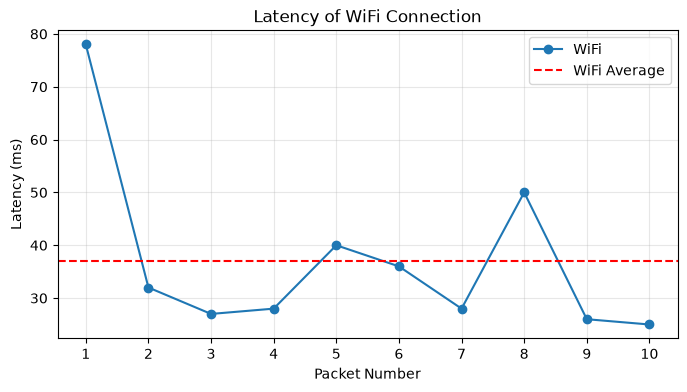

In [8]:
plt.figure(figsize=(8, 4))

plt.plot(
    range(1, len(wifi_latencies) + 1),
    wifi_latencies,
    marker="o",
    label="WiFi"
)

plt.axhline(
    np.mean(wifi_latencies),
    color="red",
    linestyle="--",
    label="WiFi Average"
)

plt.xlabel("Packet Number")
plt.ylabel("Latency (ms)")
plt.title("Latency of WiFi Connection")
plt.xticks(range(1, len(wifi_latencies) + 1))
plt.grid(alpha=0.3)
plt.legend()
plt.show()


## **Step 5:** Repeat with Mobile Data

Now switch to:
- Mobile hotspot OR
- Cellular data

Repeat all previous steps and record results.

In [10]:
def run_ping(host="8.8.8.8", count=10):
    result = subprocess.run(
        ["ping", "-n", str(count), host],
        capture_output=True,
        text=True,
        errors="replace"
    )
    return result.stdout

ping_output = run_ping()
print(ping_output)


Haciendo ping a 8.8.8.8 con 32 bytes de datos:
Respuesta desde 8.8.8.8: bytes=32 tiempo=109ms TTL=114
Respuesta desde 8.8.8.8: bytes=32 tiempo=131ms TTL=114
Respuesta desde 8.8.8.8: bytes=32 tiempo=115ms TTL=114
Respuesta desde 8.8.8.8: bytes=32 tiempo=98ms TTL=114
Respuesta desde 8.8.8.8: bytes=32 tiempo=137ms TTL=114
Respuesta desde 8.8.8.8: bytes=32 tiempo=124ms TTL=114
Respuesta desde 8.8.8.8: bytes=32 tiempo=123ms TTL=114
Respuesta desde 8.8.8.8: bytes=32 tiempo=90ms TTL=114
Respuesta desde 8.8.8.8: bytes=32 tiempo=87ms TTL=114
Respuesta desde 8.8.8.8: bytes=32 tiempo=104ms TTL=114

Estad¡sticas de ping para 8.8.8.8:
    Paquetes: enviados = 10, recibidos = 10, perdidos = 0
    (0% perdidos),
Tiempos aproximados de ida y vuelta en milisegundos:
    M¡nimo = 87ms, M ximo = 137ms, Media = 111ms



In [11]:
def extract_latencies(ping_text):
    times = re.findall(r"(?:tiempo|time)=(\d+(?:\.\d+)?)", ping_text)
    return [float(t) for t in times]

latencies = extract_latencies(ping_output)
print(latencies)

[109.0, 131.0, 115.0, 98.0, 137.0, 124.0, 123.0, 90.0, 87.0, 104.0]


In [14]:
lat_array = np.array(latencies)

avg_latency = np.mean(lat_array)
std_latency = np.std(lat_array)
jitter = np.mean(np.abs(np.diff(lat_array)))

print(f"Average latency: {avg_latency:.2f} ms")
print(f"Standard deviation: {std_latency:.2f} ms")
print(f"Jitter: {jitter:.2f} ms")

# Save mobile data measurements for comparison
mobile_latencies = lat_array.copy()

Average latency: 111.80 ms
Standard deviation: 16.24 ms
Jitter: 17.89 ms


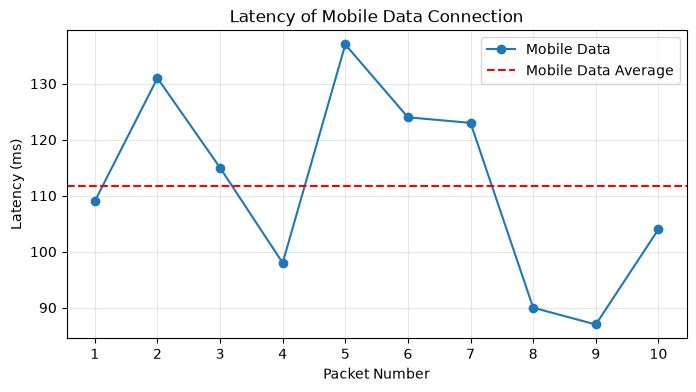

In [15]:
plt.figure(figsize=(8, 4))

plt.plot(
    range(1, len(mobile_latencies) + 1),
    mobile_latencies,
    marker="o",
    label="Mobile Data"
)

plt.axhline(
    np.mean(mobile_latencies),
    color="red",
    linestyle="--",
    label="Mobile Data Average"
)

plt.xlabel("Packet Number")
plt.ylabel("Latency (ms)")
plt.title("Latency of Mobile Data Connection")
plt.xticks(range(1, len(mobile_latencies) + 1))
plt.grid(alpha=0.3)
plt.legend()
plt.show()


## Analysis Questions

Answer the following:

**1. Which network had lower latency? Why?**  
  
WiFi had lower average latency: 37.00 ms compared with 111.80 ms for mobile data. During this test, the WiFi connection provided a shorter round-trip time. The difference could be related to network load, signal conditions, or the route to the destination, but the ping measurements alone cannot identify the exact cause.

**2. Which network was more stable (lower standard deviation)?**  
WiFi was slightly more stable. Its standard deviation was 15.53 ms, compared with 16.24 ms for mobile data. Both connections had a similar amount of absolute variation around their average latency.

**3. Which network had higher jitter?**  
Mobile data had higher jitter: 17.89 ms compared with 13.67 ms for WiFi. Therefore, the response times changed more between consecutive packets on the mobile connection.

**4. Based on your latency, jitter, and stability results, what can you infer about signal strength (SNR) and interference?**  

WiFi showed lower latency and slightly lower variability, which could be consistent with more favorable signal conditions or less interference. However, SNR measures signal power relative to noise power, and it was not measured directly. Network congestion and routing could also explain the results, so we cannot conclude that mobile data had lower SNR.

**5. Why might mobile networks behave differently than WiFi?**  
Mobile networks use cellular infrastructure and share radio resources among users. Their performance can vary with coverage, distance from the base station, network load, and mobility. In this experiment, the mobile hotspot also added a wireless connection between the computer and the phone. 

**6. How does this relate to SNR and BER?**  
SNR is the signal-to-noise ratio, and BER is the bit error rate. For the same modulation and coding conditions, higher SNR generally leads to lower BER. Poor signal conditions can cause transmission errors and retransmissions, increasing latency and jitter. However, this experiment did not measure SNR or BER. Both tests had 0% ping packet loss, which does not prove that no wireless bit errors occurred.

**7. Why could TCP misinterpret wireless losses as congestion?**  
TCP commonly treats packet loss as a sign of network congestion. Wireless interference or weak signals can also cause losses, but TCP may not distinguish their cause. It may reduce its sending rate even when congestion is not responsible, lowering throughput. This is a theoretical explanation: our ping tests used ICMP and did not directly test TCP behavior.

## **Evaluation Rubric**

| Criteria | Points |
|---------|--------|
| Data collection (WiFi + Mobile) | 1 |
| Correct metric computation, plot and visualization | 1 |
| Answers and analysis quality **(individual)** | 3 |

Total: 5 points